# Etapa 3 — Modelagem

Entrada: `../data/processed/dataset.csv`, da Etapa 2.
Saída: um classificador treinado, avaliado e interpretado, e um ranking dos
melhores horários da janela.

Um detalhe que define esta etapa: **não existe label pronta.** O site
classifica as condições para pesca, não para surf — e pesca gosta de mar
calmo, quase o oposto. Definir o que é uma condição boa para surfar é a
primeira tarefa aqui, e é uma decisão sua.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score

BASE = Path.cwd().resolve()
if not (BASE / "data" / "processed").exists():
    BASE = BASE.parent
DIR_PROC = BASE / "data" / "processed"

In [2]:
df = pd.read_csv(DIR_PROC / "dataset.csv", parse_dates=["data_hora"])
df = df.sort_values("data_hora").reset_index(drop=True)
print("Linhas:", len(df), "| Colunas:", df.columns.tolist())
print("Nulos:", df.isna().sum().to_dict())
display(df.head())

Linhas: 168 | Colunas: ['data_hora', 'altura_onda', 'direcao_onda', 'velocidade_vento', 'direcao_vento', 'altura_mare', 'hora', 'dia_semana', 'data', 'periodo']
Nulos: {'data_hora': 0, 'altura_onda': 0, 'direcao_onda': 0, 'velocidade_vento': 0, 'direcao_vento': 0, 'altura_mare': 0, 'hora': 0, 'dia_semana': 0, 'data': 0, 'periodo': 0}


,data_hora,altura_onda,direcao_onda,velocidade_vento,direcao_vento,altura_mare,hora,dia_semana,data,periodo
0,2026-10-11 00:00:00,1.0,ESE,21.0,SE,0.942725,0,6,2026-10-11,madrugada
1,2026-10-11 01:00:00,1.0,ESE,22.0,SE,1.275289,1,6,2026-10-11,madrugada
2,2026-10-11 02:00:00,1.0,ESE,20.0,SE,1.607852,2,6,2026-10-11,madrugada
3,2026-10-11 03:00:00,1.0,ESE,17.0,ESE,1.940416,3,6,2026-10-11,madrugada
4,2026-10-11 04:00:00,1.0,ESE,21.0,ESE,2.272979,4,6,2026-10-11,madrugada


## 1. Carregar o dataset processado

Confira que veio o que você espera: número de linhas, tipos, nulos. Se a
Etapa 2 mudou, isso aparece aqui.

## 2. Definir a label — regra heurística inicial

Como não há observações reais de qualidade para surf, defino uma **heurística didática, não validada**: onda de 0,8–2,0 m e vento até 15 km/h → *ótima*; onda de 0,5–2,5 m e vento até 25 km/h → *boa*; demais → *ruim*. As faixas são suposições iniciais e podem não servir para iniciantes, praias ou condições locais específicas. Maré e direções entram como características auxiliares, mas não determinam esta label. O classificador apenas aprende a reproduzir esta regra, não prevê condições futuras independentes.

In [3]:
def classe_surf(linha):
    onda, vento = linha["altura_onda"], linha["velocidade_vento"]
    if 0.8 <= onda <= 2.0 and vento <= 15:
        return "otima"
    if 0.5 <= onda <= 2.5 and vento <= 25:
        return "boa"
    return "ruim"

df["classe"] = df.apply(classe_surf, axis=1)
print(df["classe"].value_counts().to_string())
print((df["classe"].value_counts(normalize=True)*100).round(1).astype(str) + "%")

classe
boa      148
ruim      19
otima      1
classe
boa      88.1%
ruim     11.3%
otima     0.6%
Name: proportion, dtype: str


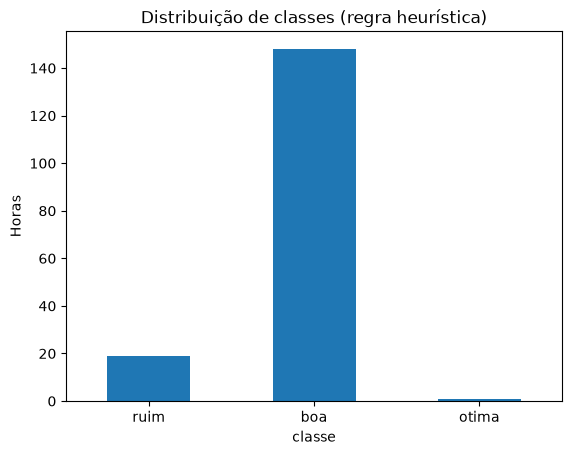

In [4]:
df["classe"].value_counts().reindex(["ruim", "boa", "otima"], fill_value=0).plot.bar(
    title="Distribuição de classes (regra heurística)", rot=0)
plt.ylabel("Horas"); plt.show()

## 3. Features e alvo

Uso altura de onda, vento, maré interpolada, hora e direções. As direções textuais são codificadas por **one-hot encoding**, sem ordem artificial. Como a label foi criada principalmente a partir de onda e vento, espera-se que os modelos aprendam os mesmos limiares; resultados elevados não provam capacidade de prever surf real.

In [5]:
num_cols = [c for c in ["altura_onda", "velocidade_vento", "altura_mare", "hora"] if c in df]
cat_cols = [c for c in ["direcao_onda", "direcao_vento", "periodo"] if c in df]
X = df[num_cols + cat_cols].copy()
for c in cat_cols:
    X[c] = X[c].fillna("desconhecida").astype(str)
y = df["classe"]
print("Features:", X.columns.tolist())

Features: ['altura_onda', 'velocidade_vento', 'altura_mare', 'hora', 'direcao_onda', 'direcao_vento', 'periodo']


## 4. Treino e teste

Separação **cronológica** (primeiros 70% para treino, 30% finais para teste), pois misturar horas do mesmo dia aleatoriamente causaria vazamento temporal. Com uma janela de aproximadamente sete dias, a avaliação é instável. Se as classes do treino não variarem, não há dados suficientes para comparar classificadores de forma informativa.

In [6]:
corte = int(len(df)*0.7)
if corte < 2 or len(df)-corte < 2:
    raise ValueError("Dados insuficientes para separar treino e teste")
X_train, X_test = X.iloc[:corte], X.iloc[corte:]
y_train, y_test = y.iloc[:corte], y.iloc[corte:]
print("Treino:", len(X_train), "| Teste:", len(X_test))
print("Classes treino:", y_train.value_counts().to_dict())
print("Classes teste:", y_test.value_counts().to_dict())
if y_train.nunique() < 2:
    print("AVISO: treino contém uma única classe; resultados não são generalizáveis")

Treino: 117 | Teste: 51
Classes treino: {'boa': 102, 'ruim': 15}
Classes teste: {'boa': 46, 'ruim': 4, 'otima': 1}


## 5. Treinar

Treine pelo menos dois modelos de famílias diferentes (por exemplo uma árvore
e um modelo baseado em distância) para ter com o que comparar.

In [7]:
def preprocessor():
    return ColumnTransformer([
        ("numericas", StandardScaler(), num_cols),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])
modelos = {
    "Arvore": Pipeline([("pre", preprocessor()),
                       ("modelo", DecisionTreeClassifier(max_depth=4, min_samples_leaf=3, random_state=42))]),
    "KNN": Pipeline([("pre", preprocessor()),
                    ("modelo", KNeighborsClassifier(n_neighbors=min(5, len(X_train))) )])
}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(nome, "treinado")

Arvore treinado
KNN treinado


In [8]:
predicoes = {nome: modelo.predict(X_test) for nome, modelo in modelos.items()}
metricas = pd.DataFrame({nome: {"acuracia_balanceada": balanced_accuracy_score(y_test, pred),
                                   "acuracia": (pred == y_test).mean()}
                          for nome, pred in predicoes.items()}).T
display(metricas.round(3))

,acuracia_balanceada,acuracia
Arvore,0.667,0.980
KNN,0.417,0.922


## 6. Avaliar

- Acurácia é suficiente aqui, com as classes desbalanceadas como estão?
- Olhe a matriz de confusão: que erro o modelo comete?
- Um único split é confiável com poucas linhas, ou vale validação cruzada?


=== Arvore ===
              precision    recall  f1-score   support

         boa       0.98      1.00      0.99        46
       otima       0.00      0.00      0.00         1
        ruim       1.00      1.00      1.00         4

    accuracy                           0.98        51
   macro avg       0.66      0.67      0.66        51
weighted avg       0.96      0.98      0.97        51



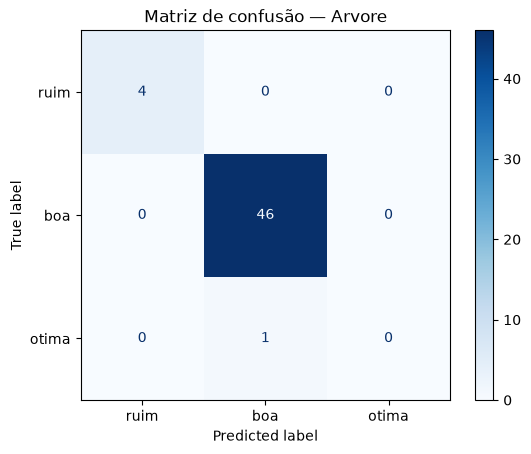


=== KNN ===
              precision    recall  f1-score   support

         boa       0.92      1.00      0.96        46
       otima       0.00      0.00      0.00         1
        ruim       1.00      0.25      0.40         4

    accuracy                           0.92        51
   macro avg       0.64      0.42      0.45        51
weighted avg       0.91      0.92      0.90        51



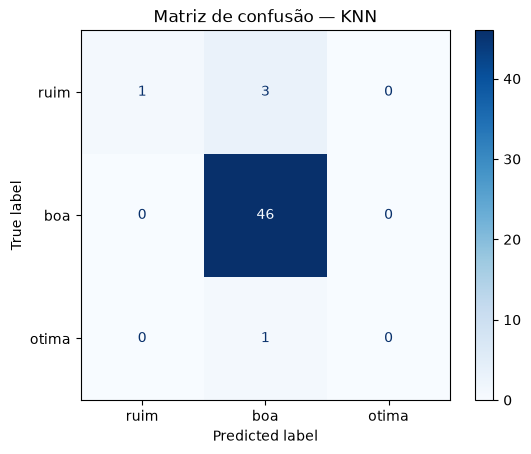

In [9]:
for nome, pred in predicoes.items():
    print(f"\n=== {nome} ===")
    print(classification_report(y_test, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, pred,
        labels=[c for c in ["ruim", "boa", "otima"] if c in set(y_test) | set(pred)],
        cmap="Blues")
    plt.title(f"Matriz de confusão — {nome}")
    plt.show()

In [10]:
print("Avaliação temporal: um único bloco final como teste.")
print("A janela é curta para validação cruzada temporal confiável;")
print("não interprete acurácia alta como confirmação de condições boas de surf.")

Avaliação temporal: um único bloco final como teste.
A janela é curta para validação cruzada temporal confiável;
não interprete acurácia alta como confirmação de condições boas de surf.


## 7. Interpretar

Um modelo que acerta e você não sabe por quê não serve para responder nada.

- Plote a árvore. Os cortes que ela encontrou parecem com os seus limiares?
- Quais features o modelo considera mais importantes? Bate com sua intuição?
- Se a acurácia veio altíssima, explique o motivo — não celebre.

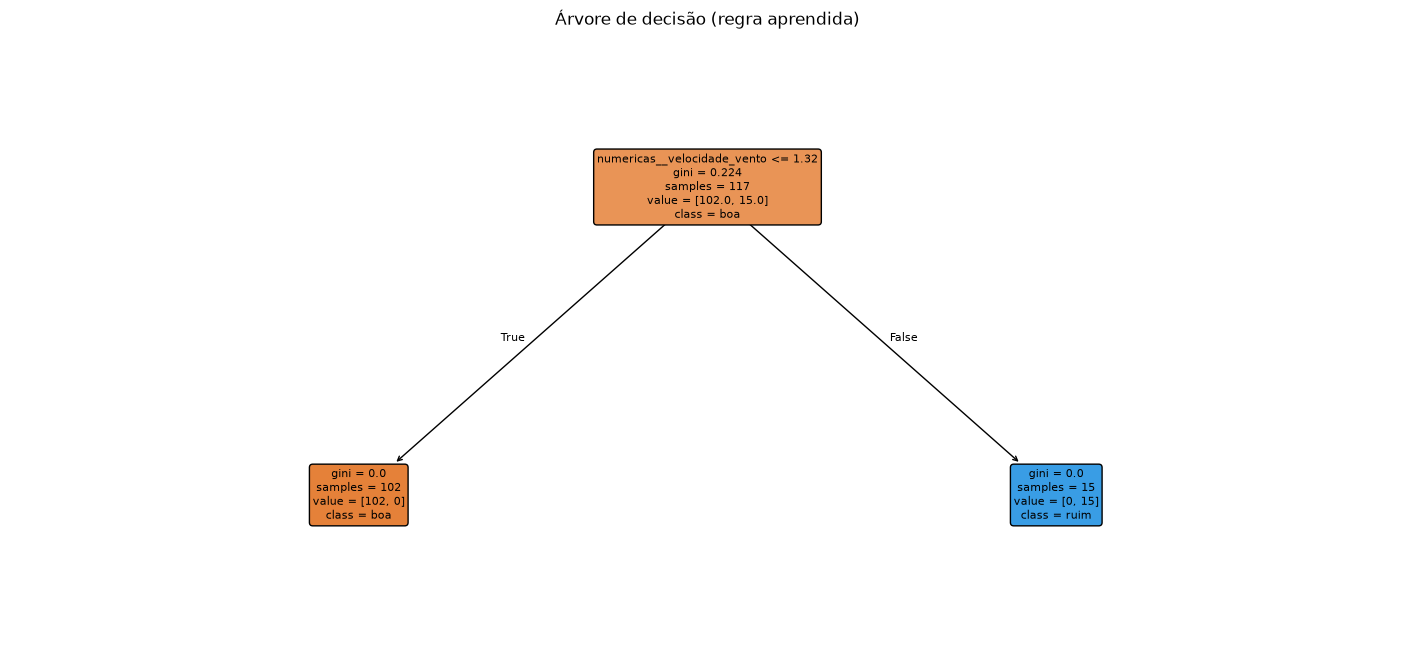

In [11]:
arvore = modelos["Arvore"]
nomes = arvore.named_steps["pre"].get_feature_names_out()
plt.figure(figsize=(18, 8))
plot_tree(arvore.named_steps["modelo"], feature_names=nomes,
          class_names=[str(x) for x in arvore.named_steps["modelo"].classes_],
          filled=True, rounded=True, fontsize=8)
plt.title("Árvore de decisão (regra aprendida)")
plt.show()

numericas__velocidade_vento       1.0
numericas__altura_onda            0.0
numericas__altura_mare            0.0
numericas__hora                   0.0
categoricas__direcao_onda_E       0.0
categoricas__direcao_onda_ESE     0.0
categoricas__direcao_vento_E      0.0
categoricas__direcao_vento_ENE    0.0
categoricas__direcao_vento_ESE    0.0
categoricas__direcao_vento_SE     0.0
dtype: float64

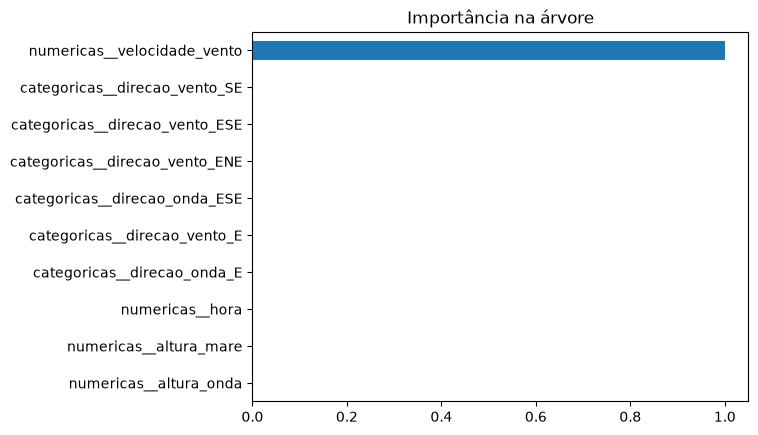

In [12]:
importancias = pd.Series(arvore.named_steps["modelo"].feature_importances_, index=nomes)
display(importancias.sort_values(ascending=False).head(10).round(3))
importancias.nlargest(10).sort_values().plot.barh(title="Importância na árvore")
plt.show()

## 8. Responder a pergunta

Aplique o modelo na janela inteira e produza a resposta para Felipe e Nicholas:

- Quais os melhores dias da janela de previsão?
- Em média, qual o melhor horário do dia?
- Em que grau essa resposta é uma previsão do mar, e em que grau é apenas a
  sua regra reescrita?

In [13]:
# O ranking principal usa diretamente a heurística: é mais transparente do que
# fingir que a predição do modelo aprendeu uma qualidade de surf observada.
pontuacao = {"ruim": 0, "boa": 1, "otima": 2}
df["pontuacao"] = df["classe"].map(pontuacao)
melhores_dias = df.groupby("data").agg(
    nota_media=("pontuacao", "mean"), horas=("pontuacao", "size"),
    onda_media=("altura_onda", "mean"), vento_medio=("velocidade_vento", "mean")
).sort_values(["nota_media", "horas"], ascending=[False, False])
melhores_horas = df.groupby("hora").agg(
    nota_media=("pontuacao", "mean"), observacoes=("pontuacao", "size")
).sort_values("nota_media", ascending=False)
print("Ranking de dias (dentro da janela coletada):")
display(melhores_dias.round(2))
print("Ranking de horas:")
display(melhores_horas.round(2))

Ranking de dias (dentro da janela coletada):


,nota_media,horas,onda_media,vento_medio
data,,,,
2026-10-14,1.00,24,1.34,19.79
2026-10-16,1.00,24,1.26,21.79
2026-10-17,1.00,24,1.18,19.83
2026-10-12,0.88,24,1.21,22.96
2026-10-15,0.88,24,1.32,21.00
2026-10-11,0.75,24,1.00,23.04
2026-10-13,0.75,24,1.22,22.79


Ranking de horas:


,nota_media,observacoes
hora,,
15,1.14,7
4,1.00,7
18,1.00,7
17,1.00,7
13,1.00,7
12,1.00,7
11,1.00,7
14,1.00,7
20,1.00,7


In [14]:
modelo_vencedor = max(metricas.index, key=lambda nome: metricas.loc[nome, "acuracia_balanceada"])
df["classe_modelo"] = modelos[modelo_vencedor].predict(X)
df[["data_hora", "classe", "classe_modelo", "altura_onda", "velocidade_vento"]].to_csv(
    DIR_PROC / "ranking_surf.csv", index=False)
print("Modelo selecionado:", modelo_vencedor)
print("Ranking exportado:", DIR_PROC / "ranking_surf.csv")
print("Melhor dia pela heurística:", melhores_dias.index[0])
print("Melhor hora média pela heurística:", melhores_horas.index[0])

Modelo selecionado: Arvore
Ranking exportado: C:\Users\Eduardo\miniprojeto2\data\processed\ranking_surf.csv
Melhor dia pela heurística: 2026-10-14
Melhor hora média pela heurística: 15


## 9. Conclusão e limites

**Recomendação:** consultar o primeiro dia do ranking e as primeiras horas do ranking calculados acima, sempre conferindo as condições reais antes de entrar na água. A pontuação é uma **heurística inicial**, não uma avaliação de surfistas; o ML apenas reproduz aproximadamente a regra criada para a label. O desempenho é limitado por poucos dias, autocorrelação temporal e ausência de rótulos reais. Não é possível inferir a melhor época **do ano** a partir de uma previsão de ~7 dias. Seria preciso reunir meses/anos de séries de onda, período, direção, vento, maré e avaliações de qualidade de surf por praia, com validação temporal fora da amostra.